# 05 · Descriptive & inferential statistics
Two pre-defined investigations, each documented as: **question → hypotheses → test & why → assumptions → statistic/p → effect size/CI → plain-English conclusion.**

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import seaborn as sns
import olist
olist.setup_plots()
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 40
from scipy import stats
from statsmodels.stats.multitest import multipletests
f = pd.read_csv(olist.PROCESSED / "order_facts.csv.gz", parse_dates=olist.ORDER_DATE_COLS)
d = f[f.is_delivered].copy()

## A · Descriptive statistics (delivered orders)

In [2]:
cols = {"item_revenue":"Item value (R$)", "freight":"Freight (R$)", "payment_value":"Payment value (R$)", "delivery_days":"Delivery days", "review_score":"Review score (1-5)"}
rows = {}
for c, lab in cols.items():
    s = d[c].dropna(); q1, q3 = s.quantile([.25,.75]); iqr = q3-q1
    rows[lab] = dict(n=len(s), mean=s.mean(), median=s.median(), std=s.std(), variance=s.var(), min=s.min(), max=s.max(), range=s.max()-s.min(),
                     Q1=q1, Q3=q3, IQR=iqr, skew=s.skew(), kurtosis=s.kurt(), outliers_pct=100*((s<q1-1.5*iqr)|(s>q3+1.5*iqr)).mean())
desc = pd.DataFrame(rows).T
desc

,n,mean,median,std,variance,min,max,range,Q1,Q3,IQR,skew,kurtosis,outliers_pct
Item value (R$),"96,470.00",137.04,86.50,209.05,"43,702.99",0.85,"13,440.00","13,439.15",45.90,149.90,104.00,9.89,277.00,7.94
Freight (R$),"96,470.00",22.79,17.17,21.56,464.83,0.00,"1,794.96","1,794.96",13.85,24.02,10.17,12.28,585.98,10.05
Payment value (R$),"96,469.00",159.86,105.28,218.82,"47,882.60",9.59,"13,664.08","13,654.49",61.88,176.33,114.45,9.37,249.19,7.85
Delivery days,"96,470.00",12.56,10.22,9.55,91.13,0.53,209.63,209.10,6.77,15.72,8.95,3.83,39.32,5.08
Review score (1-5),"95,824.00",4.16,5.00,1.28,1.65,1.00,5.00,4.00,4.00,5.00,1.00,-1.48,0.96,12.81


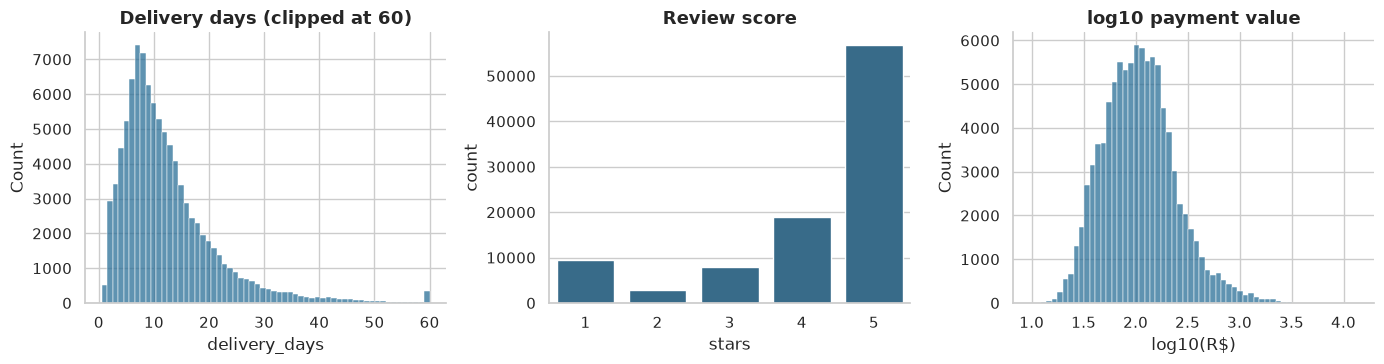

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
sns.histplot(d.delivery_days.dropna().clip(upper=60), bins=60, ax=axes[0], color="#2a6f97"); axes[0].set_title("Delivery days (clipped at 60)")
sns.countplot(x=d.review_score.dropna().astype(int), ax=axes[1], color="#2a6f97"); axes[1].set_title("Review score"); axes[1].set_xlabel("stars")
sns.histplot(np.log10(d.payment_value.dropna().clip(lower=1)), bins=60, ax=axes[2], color="#2a6f97"); axes[2].set_title("log10 payment value"); axes[2].set_xlabel("log10(R$)")
plt.tight_layout(); olist.save_fig(fig, "14_distributions.png")

### Correlation (Spearman — robust to skew and valid for ordinal data)

delivery_days      -0.23
days_vs_estimate   -0.18
n_items            -0.11
freight            -0.09
item_revenue       -0.03
max_installments   -0.02


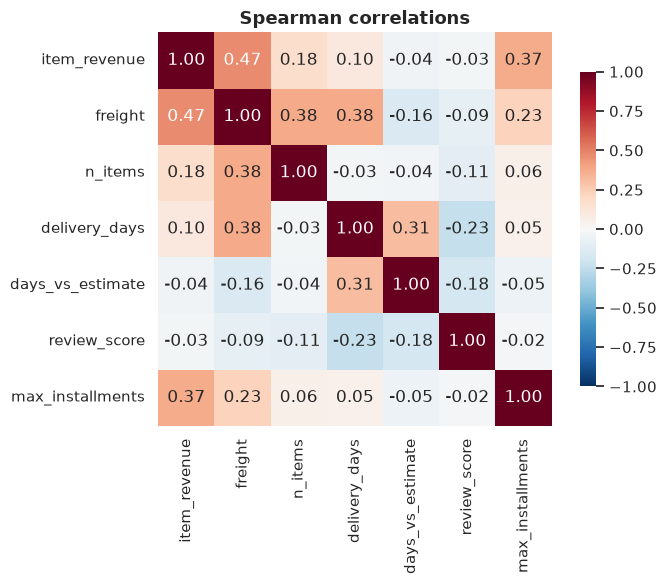

In [4]:
cm = d[["item_revenue","freight","n_items","delivery_days","days_vs_estimate","review_score","max_installments"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, square=True, cbar_kws={"shrink": .8})
ax.set_title("Spearman correlations"); plt.tight_layout(); olist.save_fig(fig, "15_correlation_heatmap.png")
print(cm["review_score"].drop("review_score").sort_values().round(3).to_string())

*Correlation ≠ causation:* a slow delivery may coincide with distance, seller or category effects. See the printed coefficients above for the review-score relationships.

---
## B · Investigation 1 — Does late delivery lower review scores?
**Question.** Among delivered orders with a review, do orders delivered **after** the estimated date get lower review scores?

**Definition.** `late` = `order_delivered_customer_date > order_estimated_delivery_date`.

**Hypotheses.** H₀: mean(score | late) = mean(score | not late). H₁: they differ (two-sided).

**Test choice.** Welch's t-test (unequal variances) for the mean difference + CI, with **Mann–Whitney U** as the robustness check because scores are ordinal and non-normal.

In [5]:
r = d.dropna(subset=["review_score"])
late = r[r.is_late == 1].review_score; ont = r[r.is_late == 0].review_score
print(f"Sample sizes: late n={len(late):,} | on-time n={len(ont):,}")
print(f"Means: late {late.mean():.3f} | on-time {ont.mean():.3f} | difference {late.mean()-ont.mean():+.3f}")
print(f"Medians: late {late.median():.0f} | on-time {ont.median():.0f}")
lev = stats.levene(late, ont)
print(f"\nLevene equal-variance test: W={lev.statistic:.1f}, p={lev.pvalue:.2e}")
print(f"Std: late {late.std():.3f} | on-time {ont.std():.3f}; skew late {late.skew():.2f}, on-time {ont.skew():.2f}")
t = stats.ttest_ind(late, ont, equal_var=False)
se = np.sqrt(late.var()/len(late) + ont.var()/len(ont)); diff = late.mean()-ont.mean()
dfw = se**4 / ((late.var()/len(late))**2/(len(late)-1) + (ont.var()/len(ont))**2/(len(ont)-1))
ci = diff + np.array([-1, 1]) * stats.t.ppf(.975, dfw) * se
pooled = np.sqrt(((len(late)-1)*late.var() + (len(ont)-1)*ont.var())/(len(late)+len(ont)-2))
print(f"\nWelch t = {t.statistic:.2f}, p = {t.pvalue:.2e}")
print(f"95% CI for mean difference: [{ci[0]:.3f}, {ci[1]:.3f}]")
print(f"Cohen's d = {diff/pooled:.2f}")
u = stats.mannwhitneyu(late, ont, alternative="two-sided")
cles = u.statistic / (len(late)*len(ont))
print(f"\nMann-Whitney U = {u.statistic:,.0f}, p = {u.pvalue:.2e}")
print(f"P(random late order scores higher than random on-time, ties=.5) = {cles:.3f}; rank-biserial r = {2*cles-1:+.3f}")
rng = np.random.default_rng(42)
bs = [rng.choice(late, len(late)).mean() - rng.choice(ont, len(ont)).mean() for _ in range(2000)]
print(f"Bootstrap 95% CI (2000 resamples): [{np.percentile(bs,2.5):.3f}, {np.percentile(bs,97.5):.3f}]")
print(f"\n1-2 star share: late {(late<=2).mean():.1%} vs on-time {(ont<=2).mean():.1%}")

Sample sizes: late n=7,661 | on-time n=88,163
Means: late 2.565 | on-time 4.294 | difference -1.729
Medians: late 2 | on-time 5

Levene equal-variance test: W=3381.5, p=0.00e+00
Std: late 1.658 | on-time 1.147; skew late 0.39, on-time -1.74



Welch t = -89.41, p = 0.00e+00
95% CI for mean difference: [-1.767, -1.691]
Cohen's d = -1.45

Mann-Whitney U = 150,706,850, p = 0.00e+00
P(random late order scores higher than random on-time, ties=.5) = 0.223; rank-biserial r = -0.554


Bootstrap 95% CI (2000 resamples): [-1.767, -1.690]

1-2 star share: late 54.1% vs on-time 9.2%


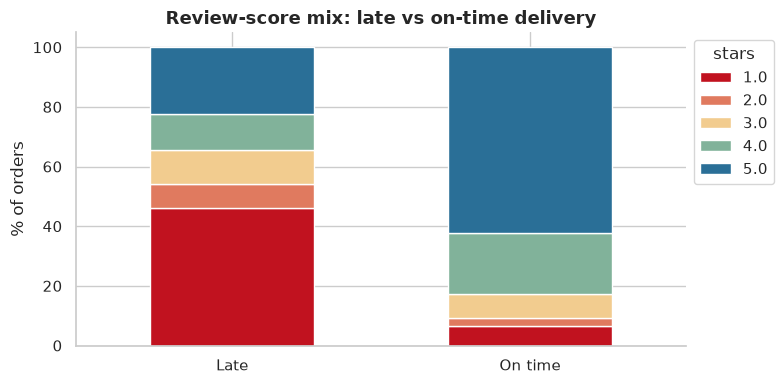

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
mix = pd.crosstab(r.is_late.map({0:"On time", 1:"Late"}), r.review_score, normalize="index")*100
mix.plot(kind="bar", stacked=True, color=["#c1121f","#e07a5f","#f2cc8f","#81b29a","#2a6f97"], ax=ax, width=.55)
ax.set_ylabel("% of orders"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0); ax.legend(title="stars", bbox_to_anchor=(1,1), loc="upper left")
ax.set_title("Review-score mix: late vs on-time delivery"); plt.tight_layout(); olist.save_fig(fig, "16_test1_late_vs_ontime.png")

**Conclusion.** See `**Conclusion 1 (plain English).** Late orders average **2.57★ vs 4.29★** for on-time orders — a difference of **−1.73 stars (95% CI −1.77 to −1.69; bootstrap CI identical)**. Welch's t-test and the rank-based Mann–Whitney test both give p < 10⁻³⁰⁰ (reported as 0.0 by floating point), so we **reject H₀**.

**Effect size is large:** Cohen's d = −1.45; a randomly chosen late order out-scores a randomly chosen on-time order only **22%** of the time (rank-biserial r = −0.55). 54% of late orders get 1–2★ vs 9% of on-time orders.

**Caveats.** (1) With ~96k orders almost anything is "significant" — it is the *size* that matters here. (2) Observational data: lateness is associated with, not proven to cause, lower scores (distance, seller and category may confound). (3) Levene's test shows unequal variances and on-time scores are strongly left-skewed (−1.74), which is why we did not rely on the t-test alone. (4) ~0.7% of delivered orders have no review.` placeholder below — filled from the printed results.

**Conclusion 1 (plain English).** Late orders average **2.57★ vs 4.29★** for on-time orders — a difference of **−1.73 stars (95% CI −1.77 to −1.69; bootstrap CI identical)**. Welch's t-test and the rank-based Mann–Whitney test both give p < 10⁻³⁰⁰ (reported as 0.0 by floating point), so we **reject H₀**.

**Effect size is large:** Cohen's d = −1.45; a randomly chosen late order out-scores a randomly chosen on-time order only **22%** of the time (rank-biserial r = −0.55). 54% of late orders get 1–2★ vs 9% of on-time orders.

**Caveats.** (1) With ~96k orders almost anything is "significant" — it is the *size* that matters here. (2) Observational data: lateness is associated with, not proven to cause, lower scores (distance, seller and category may confound). (3) Levene's test shows unequal variances and on-time scores are strongly left-skewed (−1.74), which is why we did not rely on the t-test alone. (4) ~0.7% of delivered orders have no review.

---
## C · Investigation 2 — Does payment value differ by payment type?
**Question.** Do total order payment values differ across the main payment type used (credit card, boleto, debit card, voucher)?

**Unit.** One row per delivered order; `main_payment_type` = type of its largest payment row. `not_defined` (n=3) and zero-value payments are excluded.

**Hypotheses.** H₀: the distribution of payment value is the same in all types. H₁: at least one differs.

**Test choice.** One-way ANOVA assumes ~normal residuals and equal variances. Payment values are severely right-skewed, so we check assumptions and use **Kruskal–Wallis** as primary; ANOVA on log-values is a sensitivity check; post-hoc pairwise Mann–Whitney with **Holm** correction.

In [7]:
p = d[d.main_payment_type.isin(["credit_card","boleto","debit_card","voucher"])].dropna(subset=["payment_value"])
p = p[p.payment_value > 0]
g = p.groupby("main_payment_type").payment_value
print(g.agg(["count","mean","median","std","skew"]).round(2).to_string())
groups = [x.values for _, x in g]
lv, lvl = stats.levene(*groups), stats.levene(*[np.log(x) for x in groups])
print(f"\nLevene raw: W={lv.statistic:.1f}, p={lv.pvalue:.1e} | Levene log: W={lvl.statistic:.1f}, p={lvl.pvalue:.1e}")
print("Raw skew", round(p.payment_value.skew(),1), "| log skew", round(np.log(p.payment_value).skew(),2))

                   count   mean  median    std  skew
main_payment_type                                   
boleto             19191 144.33   93.78 212.95 11.05
credit_card        72818 166.18  109.41 222.44  8.95
debit_card          1483 140.27   89.62 234.79 10.34
voucher             2977 114.86   81.36 129.74  5.23

Levene raw: W=48.9, p=1.5e-31 | Levene log: W=11.8, p=1.1e-07
Raw skew 9.4 | log skew 0.52


In [8]:
kw = stats.kruskal(*groups)
n = len(p); k = len(groups)
eps2 = (kw.statistic - k + 1) / (n - k)
print(f"Kruskal-Wallis H = {kw.statistic:.1f}, df = {k-1}, p = {kw.pvalue:.2e}, epsilon^2 = {eps2:.4f}")
lg = [np.log(x) for x in groups]; allv = np.concatenate(lg)
an = stats.f_oneway(*lg)
ss_b = sum(len(x)*(x.mean()-allv.mean())**2 for x in lg); ss_t = ((allv-allv.mean())**2).sum()
print(f"ANOVA on log(value): F = {an.statistic:.1f}, p = {an.pvalue:.2e}, eta^2 = {ss_b/ss_t:.4f}")
names = list(g.groups.keys()); res = []
for i in range(k):
    for j in range(i+1, k):
        u = stats.mannwhitneyu(groups[i], groups[j], alternative="two-sided")
        res.append((names[i], names[j], np.median(groups[i]), np.median(groups[j]), u.pvalue))
pw = pd.DataFrame(res, columns=["A","B","median_A","median_B","p_raw"])
pw["p_holm"] = multipletests(pw.p_raw, method="holm")[1]
pw["significant_0.05"] = pw.p_holm < .05
pw.round(4)

Kruskal-Wallis H = 886.4, df = 3, p = 8.03e-192, epsilon^2 = 0.0092
ANOVA on log(value): F = 284.5, p = 7.16e-184, eta^2 = 0.0088


,A,B,median_A,median_B,p_raw,p_holm,significant_0.05
0,boleto,credit_card,93.78,109.41,0.00,0.00,True
1,boleto,debit_card,93.78,89.62,0.02,0.02,True
2,boleto,voucher,93.78,81.36,0.00,0.00,True
3,credit_card,debit_card,109.41,89.62,0.00,0.00,True
4,credit_card,voucher,109.41,81.36,0.00,0.00,True
5,debit_card,voucher,89.62,81.36,0.00,0.00,True


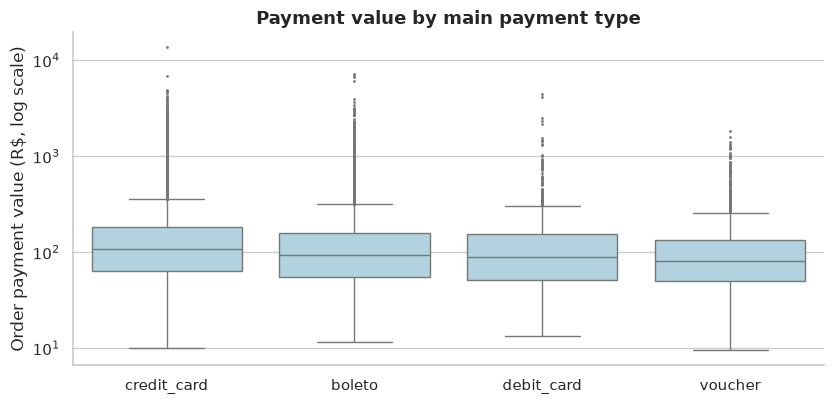

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
order = ["credit_card","boleto","debit_card","voucher"]
sns.boxplot(data=p, x="main_payment_type", y="payment_value", order=order, ax=ax, color="#a9d6e5", fliersize=1)
ax.set_yscale("log"); ax.set_xlabel(""); ax.set_ylabel("Order payment value (R$, log scale)"); ax.set_title("Payment value by main payment type")
plt.tight_layout(); olist.save_fig(fig, "17_test2_payment_by_type.png")

**Conclusion 2 (plain English).** Payment value **does differ by main payment type** (Kruskal–Wallis H = 886, p ≈ 10⁻¹⁹²; log-ANOVA agrees). After Holm correction **all six pairwise comparisons are significant** (boleto vs debit is the weakest, p ≈ 0.02). Medians: **credit card R$109 > boleto R$94 > debit R$90 > voucher R$81.**

**But the effect is tiny:** ε² = 0.009 and η² = 0.009 — payment type explains **under 1%** of the variation in order value. The p-values are small mostly because n is large; the practical difference (≈R$15–30 in median) is modest next to the spread within each group. It also shouldn't be read causally: customers pick how to pay after deciding what to buy.

**Assumptions.** Raw values are very right-skewed (skew 9.4) and variances unequal (Levene p ≈ 10⁻³¹), so a rank test is primary; the log transform removes most skew (0.52). Group sizes are all > 1,400. Orders are treated as independent (repeat customers are only ~3%).